In [1]:
import os, json, time, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
INPUT_ROOT = "/kaggle/input"
OUT = "/kaggle/working/p2_9"
os.makedirs(OUT, exist_ok=True)

SEED, N_BOOT = 2026, 1000
MIN_FACES, MIN_VIDEOS = 30, 10
K_PRIMARY = 20
MAKE_PANELS = False          # set True only if the clean crops, cams_A/C.npz and faces_manifest.csv are attached
METRICS = {"faith_20": "faithfulness score (k=20%)", "p0": "confidence in predicted class (p0)", "entropy": "heat entropy",
           "central_share": "central 6x6 heat share", "peak_share": "peak heat share",
           "stab_cos": "stability cosine (all pairs)", "stab_cos_unchanged": "stability cosine (explained class unchanged)"}

def find_one(name, roots):
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")
ROOTS = [INPUT_ROOT, REPO_DIR]
print("setup OK")

Cloning into '/kaggle/working/repo'...


setup OK


In [2]:
# ============================================================
# LOAD INPUTS, CHECK THEY BELONG TOGETHER, BUILD ONE TABLE PER CONDITION
# ============================================================
fa_meta = json.load(open(find_one("faithfulness_meta.json", ROOTS)))
st_meta = json.load(open(find_one("stability_meta.json", ROOTS)))
g_meta = json.load(open(find_one("gradcam_meta.json", ROOTS)))
for name, m in (("faithfulness", fa_meta), ("stability", st_meta)):
    assert m["model_sha256"] == g_meta["model_sha256"], f"{name} was made with a different checkpoint"
    assert m["manifest_sha256"] == g_meta["manifest_sha256"], f"{name} was made with a different manifest"
    assert abs(m["threshold"] - 0.2217) < 5e-4, f"{name}: threshold is not the frozen 0.2217"
assert fa_meta["k_primary"] == K_PRIMARY

cf = pd.read_csv(find_one("cam_face_stats.csv", ROOTS)); cf["face_id"] = cf["face_id"].astype(str)
stab = {}
for clean, comp in (("A", "B"), ("C", "D")):
    s = pd.read_csv(find_one(f"stability_{clean}_{comp}.csv", ROOTS)); s["pair_id"] = s["pair_id"].astype(str); s["face_id"] = s["face_id"].astype(str)
    stab[clean] = s.set_index("pair_id")      # clean face -> its twin's stability
    stab[comp] = s.set_index("face_id")       # compressed face -> its own stability

F = {}
for k in "ABCD":
    d = pd.read_csv(find_one(f"faithfulness_{k}.csv", ROOTS)); d["face_id"] = d["face_id"].astype(str)
    assert d["face_id"].is_unique and (d["cond"] == k).all(), f"{k}: faithfulness file is not one row per face of this condition"
    d = d[["face_id", "video_id", "outcome", "target", "p0", f"faith_{K_PRIMARY}", f"d_cam_{K_PRIMARY}", f"d_rand_{K_PRIMARY}", f"d_low_{K_PRIMARY}"]].copy()
    c = cf[cf["cond"] == k].drop_duplicates("face_id").set_index("face_id")
    for col in ("entropy", "com_y", "com_x", "central_share", "peak_share"):
        d[col] = d["face_id"].map(c[col])
    s = stab[k]
    d["stab_cos"] = d["face_id"].map(s["cos"]); d["stab_flip"] = d["face_id"].map(s["flip_target"])
    d["stab_cos_unchanged"] = np.where(d["stab_flip"].astype("boolean").fillna(True).astype(bool), np.nan, d["stab_cos"])
    d["pred_class"] = np.where(d["outcome"].isin(["TP", "FP"]), "FAKE", "REAL")
    assert d["outcome"].isin(["TP", "FP", "FN", "TN"]).all(), f"{k}: unknown outcome label"
    assert d["stab_cos"].notna().mean() > 0.99, f"{k}: stability is missing for many faces (wrong stability file?)"
    assert d["entropy"].notna().mean() > 0.99, f"{k}: descriptors are missing for many faces (wrong cam_face_stats.csv?)"
    F[k] = d
    print(f"{k}: {len(d)} faces, {d['video_id'].nunique()} videos | accuracy {(d['outcome'].isin(['TP','TN'])).mean():.3f}")
print("inputs OK | threshold", g_meta["threshold"], "| manifest", g_meta["manifest_sha256"][:8])

A: 5883 faces, 198 videos | accuracy 0.839
B: 5883 faces, 198 videos | accuracy 0.527
C: 8763 faces, 300 videos | accuracy 0.646
D: 8763 faces, 300 videos | accuracy 0.538
inputs OK | threshold 0.22168749570846558 | manifest 80eae250


In [3]:
# ============================================================
# STATISTICS FUNCTIONS
# ============================================================
def boot_mean_ci(d, col, n_boot=N_BOOT, seed=SEED):
    d = d.dropna(subset=[col])
    if len(d) == 0: return (np.nan, np.nan, np.nan)
    g = d.groupby("video_id")[col].agg(["sum", "count"]).to_numpy(float)
    if len(g) < 2: return (float(d[col].mean()), np.nan, np.nan)
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    means = g[idx, 0].sum(1) / g[idx, 1].sum(1)
    return float(g[:, 0].sum() / g[:, 1].sum()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def compare(d1, d2, col, rng):
    """Difference of means (group1 - group2) with a joint video bootstrap, plus effect sizes and a video-level rank test."""
    a, b = d1.dropna(subset=[col]), d2.dropna(subset=[col])
    if len(a) < 2 or len(b) < 2: return None
    row = {"n1": len(a), "n2": len(b), "v1": a["video_id"].nunique(), "v2": b["video_id"].nunique(),
           "mean1": float(a[col].mean()), "mean2": float(b[col].mean())}
    row["diff"] = row["mean1"] - row["mean2"]
    vids = np.union1d(a["video_id"].unique(), b["video_id"].unique()); ix = pd.Index(vids)
    def per(d):
        i = ix.get_indexer(d["video_id"]); return np.bincount(i, weights=d[col].to_numpy(float), minlength=len(vids)), np.bincount(i, minlength=len(vids))
    (s1, c1), (s2, c2) = per(a), per(b)
    idx = rng.integers(0, len(vids), (N_BOOT, len(vids))); n1, n2 = c1[idx].sum(1), c2[idx].sum(1)
    with np.errstate(all="ignore"):
        diffs = np.where((n1 > 0) & (n2 > 0), s1[idx].sum(1) / n1 - s2[idx].sum(1) / n2, np.nan)
    row["ci_lo"], row["ci_hi"] = (float(x) for x in np.nanpercentile(diffs, [2.5, 97.5]))
    U = stats.mannwhitneyu(a[col], b[col], alternative="two-sided").statistic; row["prob_sup_face"] = float(U / (len(a) * len(b)))
    g1, g2 = a.groupby("video_id")[col].mean(), b.groupby("video_id")[col].mean()
    if len(g1) >= 3 and len(g2) >= 3:
        r = stats.mannwhitneyu(g1, g2, alternative="two-sided"); row["prob_sup_video"] = float(r.statistic / (len(g1) * len(g2))); row["p_video"] = float(r.pvalue)
    else:
        row["prob_sup_video"], row["p_video"] = np.nan, np.nan
    return row

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj
print("functions ready")

functions ready


In [4]:
# ============================================================
# GROUP COUNTS AND GROUP SUMMARIES (every statistic gets its sample size)
# ============================================================
GROUPS = {"TP": ["TP"], "FP": ["FP"], "FN": ["FN"], "TN": ["TN"], "predicted FAKE (TP+FP)": ["TP", "FP"], "predicted REAL (TN+FN)": ["TN", "FN"], "ALL": ["TP", "FP", "FN", "TN"]}
counts = []
for k, d in F.items():
    for g, outs in GROUPS.items():
        sub = d[d["outcome"].isin(outs)]
        counts.append({"cond": k, "group": g, "n_faces": len(sub), "n_videos": sub["video_id"].nunique(), "share_of_condition": len(sub) / len(d),
                       "descriptive_only": len(sub) < MIN_FACES or sub["video_id"].nunique() < MIN_VIDEOS})
counts = pd.DataFrame(counts); counts.to_csv(os.path.join(OUT, "outcome_counts.csv"), index=False)
print(counts[counts["group"].isin(["TP", "FP", "FN", "TN"])].round(3).to_string(index=False))

rows = []
for k, d in F.items():
    for g, outs in GROUPS.items():
        sub = d[d["outcome"].isin(outs)]
        for col in METRICS:
            m, lo, hi = boot_mean_ci(sub, col); v = sub.dropna(subset=[col])
            rows.append({"cond": k, "group": g, "metric": col, "mean": m, "ci_lo": lo, "ci_hi": hi, "n_faces": len(v), "n_videos": v["video_id"].nunique(),
                         "descriptive_only": len(v) < MIN_FACES or v["video_id"].nunique() < MIN_VIDEOS})
gsum = pd.DataFrame(rows); gsum.to_csv(os.path.join(OUT, "outcome_group_summary.csv"), index=False)
show = gsum[(gsum["metric"] == "faith_20") & gsum["group"].isin(["TP", "FP", "FN", "TN"])]
print("\nFaithfulness (k=20) by outcome:\n", show[["cond", "group", "mean", "ci_lo", "ci_hi", "n_faces", "n_videos"]].round(3).to_string(index=False))

cond group  n_faces  n_videos  share_of_condition  descriptive_only
   A    TP     2368        98               0.403             False
   A    FP      317        50               0.054             False
   A    FN      632        59               0.107             False
   A    TN     2566        96               0.436             False
   B    TP      405        61               0.069             False
   B    FP      186        49               0.032             False
   B    FN     2595       100               0.441             False
   B    TN     2697        98               0.458             False
   C    TP     3605       150               0.411             False
   C    FP     2321       130               0.265             False
   C    FN      777       129               0.089             False
   C    TN     2060       145               0.235             False
   D    TP     1139       128               0.130             False
   D    FP      809       111               0.09

In [5]:
# ============================================================
# COMPARISONS BETWEEN GROUPS (within predicted class first; class contrast labelled as confound)
# ============================================================
COMPARISONS = [("TP vs FP", ["TP"], ["FP"], "correctness within predicted FAKE"),
               ("TN vs FN", ["TN"], ["FN"], "correctness within predicted REAL"),
               ("predicted FAKE vs predicted REAL", ["TP", "FP"], ["TN", "FN"], "class contrast (confound, not correctness)")]
rng = np.random.default_rng(SEED); rows = []
for k, d in F.items():
    for label, o1, o2, kind in COMPARISONS:
        d1, d2 = d[d["outcome"].isin(o1)], d[d["outcome"].isin(o2)]
        for col in METRICS:
            r = compare(d1, d2, col, rng)
            if r is None: continue
            r.update({"cond": k, "comparison": label, "kind": kind, "metric": col, "group1_minus_group2": f"{label.split(' vs ')[0]} - {label.split(' vs ')[1]}"})
            r["descriptive_only"] = min(r["n1"], r["n2"]) < MIN_FACES or min(r["v1"], r["v2"]) < MIN_VIDEOS
            rows.append(r)
res = pd.DataFrame(rows)
test_mask = (~res["descriptive_only"]) & res["p_video"].notna()
res["p_holm"] = np.nan; res.loc[test_mask, "p_holm"] = holm(res.loc[test_mask, "p_video"])
res["n_comparisons_tested"] = int(test_mask.sum())
res["reading"] = np.where(res["descriptive_only"], "descriptive only",
                  np.where(res["p_holm"] < 0.05, "differs (Holm p<0.05; look at the effect size)", "no clear difference"))
res = res[["cond", "comparison", "kind", "metric", "n1", "n2", "v1", "v2", "mean1", "mean2", "diff", "ci_lo", "ci_hi", "prob_sup_face", "prob_sup_video", "p_video", "p_holm",
           "n_comparisons_tested", "descriptive_only", "reading", "group1_minus_group2"]]
res.to_csv(os.path.join(OUT, "outcome_analysis.csv"), index=False)
print("comparisons tested (Holm family):", int(test_mask.sum()), "| descriptive-only comparisons:", int(res["descriptive_only"].sum()))
key = res[(res["kind"].str.startswith("correctness")) & res["metric"].isin(["faith_20", "stab_cos_unchanged", "entropy", "p0"])]
print(key[["cond", "comparison", "metric", "n1", "n2", "mean1", "mean2", "diff", "ci_lo", "ci_hi", "prob_sup_video", "p_holm", "reading"]].round(3).to_string(index=False))

comparisons tested (Holm family): 84 | descriptive-only comparisons: 0
cond comparison             metric   n1   n2  mean1  mean2   diff  ci_lo  ci_hi  prob_sup_video  p_holm                                        reading
   A   TP vs FP           faith_20 2368  317 -0.009 -0.036  0.027 -0.037  0.090           0.507   1.000                            no clear difference
   A   TP vs FP                 p0 2368  317  0.910  0.711  0.199  0.125  0.288           0.854   0.000 differs (Holm p<0.05; look at the effect size)
   A   TP vs FP            entropy 2368  317  0.742  0.690  0.052  0.027  0.079           0.784   0.000 differs (Holm p<0.05; look at the effect size)
   A   TP vs FP stab_cos_unchanged  376   48  0.617  0.579  0.038 -0.083  0.182           0.512   1.000                            no clear difference
   A   TN vs FN           faith_20 2566  632  0.190  0.265 -0.075 -0.144 -0.006           0.283   0.000 differs (Holm p<0.05; look at the effect size)
   A   TN vs FN        

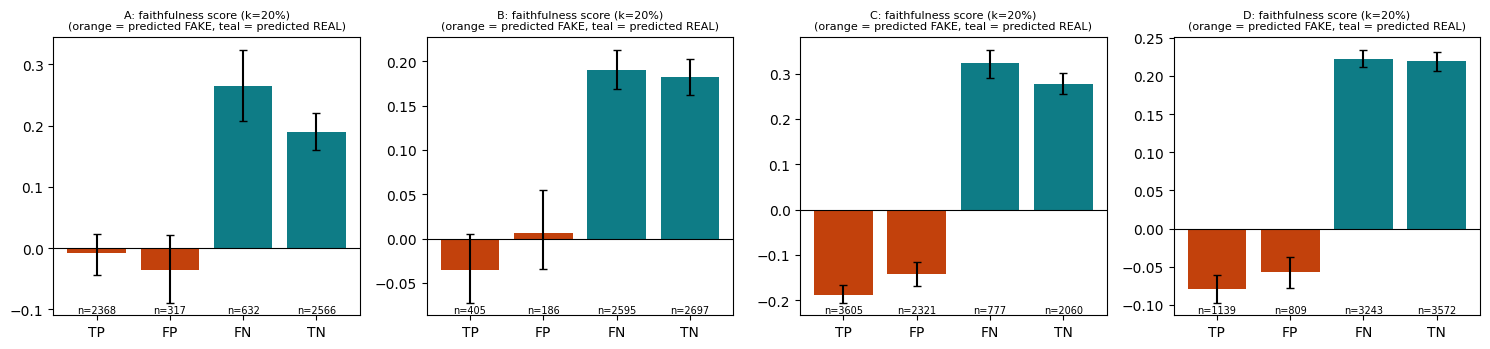

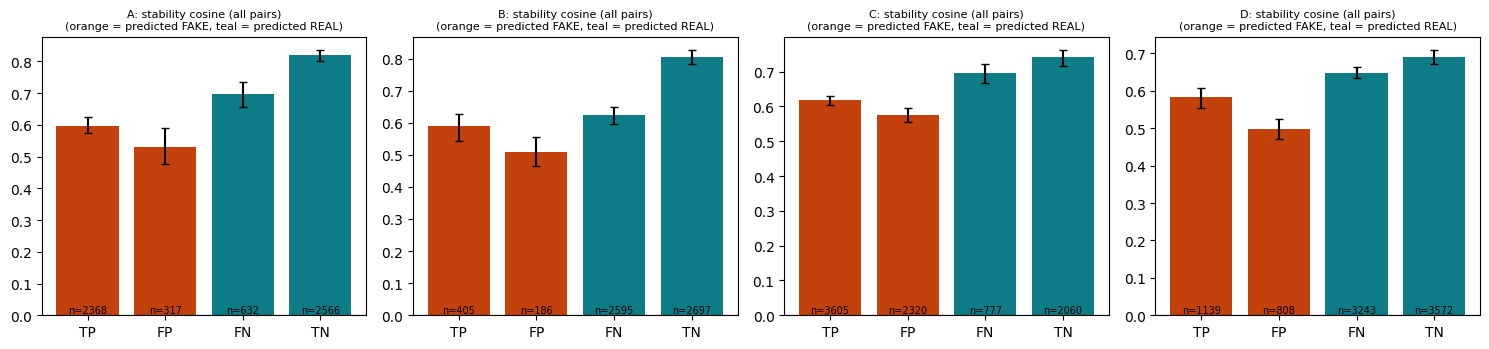

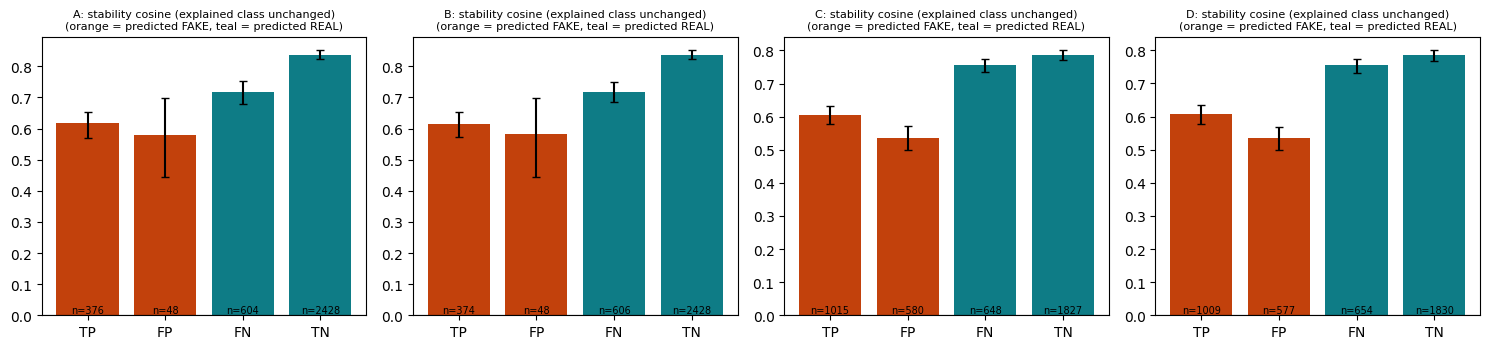

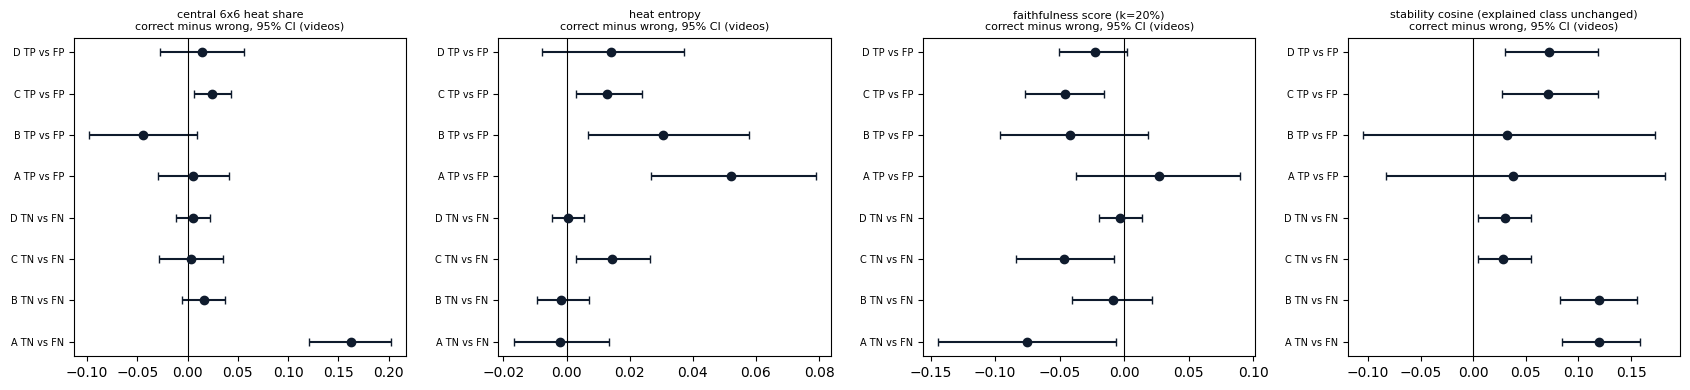

In [6]:
# ============================================================
# FIGURES
# ============================================================
def bars(ax, cond, col, groups=("TP", "FP", "FN", "TN")):
    s = gsum[(gsum["cond"] == cond) & (gsum["metric"] == col) & gsum["group"].isin(groups)].set_index("group").loc[list(groups)]
    colors = ["#C2410C" if g in ("TP", "FP") else "#0E7C86" for g in groups]
    ax.bar(groups, s["mean"], yerr=[(s["mean"] - s["ci_lo"]).fillna(0), (s["ci_hi"] - s["mean"]).fillna(0)], capsize=3, color=colors)
    ax.axhline(0, color="k", lw=0.8)
    for i, (g, r) in enumerate(s.iterrows()): ax.text(i, ax.get_ylim()[0], f"n={int(r['n_faces'])}", ha="center", va="bottom", fontsize=7)

for col, fname in (("faith_20", "outcome_faithfulness.png"), ("stab_cos", "outcome_stability.png"), ("stab_cos_unchanged", "outcome_stability_unchanged.png")):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    for ax, k in zip(axes, "ABCD"):
        bars(ax, k, col); ax.set_title(f"{k}: {METRICS[col]}\n(orange = predicted FAKE, teal = predicted REAL)", fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
sel = res[res["kind"].str.startswith("correctness") & res["metric"].isin(["faith_20", "stab_cos_unchanged", "entropy", "central_share"])]
for ax, (m, g) in zip(axes, sel.groupby("metric")):
    ypos, labels = 0, []
    for (cmp_, k), r in g.groupby(["comparison", "cond"]):
        r = r.iloc[0]; ax.errorbar(r["diff"], ypos, xerr=[[r["diff"] - r["ci_lo"]], [r["ci_hi"] - r["diff"]]], fmt="o", color="#0F1B2D", capsize=3)
        labels.append(f"{k} {cmp_}"); ypos += 1
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_title(f"{METRICS[m]}\ncorrect minus wrong, 95% CI (videos)", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "outcome_effects.png"), dpi=130); plt.show()

In [7]:
# ============================================================
# OPTIONAL OVERLAY PANELS at fixed percentiles (10th, 50th, 90th of the faithfulness score within each group). Not hand-picked.
# Needs: clean crops, cams_A.npz, cams_C.npz, faces_manifest.csv. Set MAKE_PANELS = True in the setup cell to run.
# ============================================================
if not MAKE_PANELS:
    print("Panels skipped (MAKE_PANELS = False). The numeric analysis above does not need them.")
else:
    import zipfile
    from PIL import Image
    mf = pd.read_csv(find_one("faces_manifest.csv", ROOTS)); mf["face_id"] = mf["face_id"].astype(str)
    CROPS = "/kaggle/working/crops"; os.makedirs(CROPS, exist_ok=True)
    zips = [os.path.join(d_, "step5_faces.zip") for d_, _, fs in os.walk(INPUT_ROOT) if "step5_faces.zip" in fs]
    base = INPUT_ROOT
    if zips:
        base = os.path.join(CROPS, "step5_faces")
        if not os.path.exists(os.path.join(base, ".done")):
            os.makedirs(base, exist_ok=True); zipfile.ZipFile(zips[0]).extractall(base); open(os.path.join(base, ".done"), "w").close()
    sample = mf["face_rel"].sample(12, random_state=0).tolist(); root = None
    for d_, _, _ in os.walk(base):
        if all(os.path.exists(os.path.join(d_, r)) for r in sample): root = d_; break
    assert root, "clean crops not found: attach step5_faces (folder or zip)"
    rel = mf.set_index("face_id")["face_rel"]

    def overlay(img, cam, alpha=0.5):
        up = np.asarray(Image.fromarray(cam.astype(np.float32), mode="F").resize((299, 299), Image.BICUBIC)).clip(0, 1)
        return np.clip((1 - alpha) * img / 255.0 + alpha * plt.cm.jet(up)[..., :3], 0, 1)

    for k in ("A", "C"):
        z = np.load(find_one(f"cams_{k}.npz", [INPUT_ROOT]), allow_pickle=True); idx = {str(f): i for i, f in enumerate(z["face_id"])}
        fig, axes = plt.subplots(4, 3, figsize=(7.5, 10))
        for r_, o in enumerate(("TP", "FP", "FN", "TN")):
            g = F[k][F[k]["outcome"] == o].sort_values(f"faith_{K_PRIMARY}").reset_index(drop=True)
            for c_, q in enumerate((0.10, 0.50, 0.90)):
                ax = axes[r_, c_]; ax.axis("off")
                if len(g) == 0: continue
                row = g.iloc[int(round(q * (len(g) - 1)))]
                img = np.asarray(Image.open(os.path.join(root, rel[row["face_id"]])).convert("RGB").resize((299, 299)))
                ax.imshow(overlay(img, z["cam"][idx[row["face_id"]]])); ax.set_title(f"{o} p{int(q * 100)}  faith={row[f'faith_{K_PRIMARY}']:.2f}  p0={row['p0']:.2f}", fontsize=7)
        fig.suptitle(f"{k}: overlays at the 10th / 50th / 90th percentile of the faithfulness score within each outcome (fixed rule)", fontsize=8)
        plt.tight_layout(); plt.savefig(os.path.join(OUT, f"outcome_panels_{k}.png"), dpi=120); plt.show()

Panels skipped (MAKE_PANELS = False). The numeric analysis above does not need them.


In [8]:
# ============================================================
# CHECKS + METADATA
# ============================================================
checks = []
for k, d in F.items():
    c = counts[(counts["cond"] == k) & counts["group"].isin(["TP", "FP", "FN", "TN"])]
    checks.append({"check": f"{k}: outcome groups add up to all faces", "value": int(c["n_faces"].sum()), "limit": len(d), "pass": int(c["n_faces"].sum()) == len(d)})
    checks.append({"check": f"{k}: faithfulness present for every face", "value": int(d["faith_20"].notna().sum()), "limit": len(d), "pass": bool(d["faith_20"].notna().all())})
    checks.append({"check": f"{k}: groups below {MIN_FACES} faces or {MIN_VIDEOS} videos", "value": int(c["descriptive_only"].sum()), "limit": "informational", "pass": True})
    pc_ok = (F[k]["pred_class"] == np.where(F[k]["target"] > 0, "FAKE", "REAL")).mean()
    checks.append({"check": f"{k}: predicted class from outcome agrees with Grad-CAM target", "value": round(float(pc_ok), 4), "limit": ">= 0.99", "pass": bool(pc_ok >= 0.99)})
checks.append({"check": "number of comparisons in the Holm family", "value": int(test_mask.sum()), "limit": "informational", "pass": True})
checks = pd.DataFrame(checks); checks.to_csv(os.path.join(OUT, "outcome_checks.csv"), index=False); print(checks.to_string(index=False))
json.dump({"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model_sha256": g_meta["model_sha256"], "manifest_sha256": g_meta["manifest_sha256"], "threshold": g_meta["threshold"],
           "comparisons": [c[0] + " (" + c[3] + ")" for c in COMPARISONS], "metrics": METRICS,
           "tests": "bootstrap CI over videos (joint resampling); Mann-Whitney on per-video means; Holm correction over all tested comparisons; effect size = probability of superiority",
           "min_group": {"faces": MIN_FACES, "videos": MIN_VIDEOS}, "n_comparisons_tested": int(test_mask.sum()), "panels_made": bool(MAKE_PANELS),
           "panel_rule": "fixed percentiles 10/50/90 of faith_20 within each outcome group", "seed": SEED},
          open(os.path.join(OUT, "outcome_meta.json"), "w"), indent=2)
print("\nsaved:", sorted(os.listdir(OUT)))
assert checks["pass"].all(), "AN INTEGRITY CHECK FAILED: do not start Step 2.10 until this is understood."
print("Done. Next: Step 2.10 reliability rule (write and date the rule BEFORE looking at the Trusted share).")

                                                      check     value         limit  pass
                      A: outcome groups add up to all faces 5883.0000          5883  True
                     A: faithfulness present for every face 5883.0000          5883  True
                      A: groups below 30 faces or 10 videos    0.0000 informational  True
A: predicted class from outcome agrees with Grad-CAM target    0.9995       >= 0.99  True
                      B: outcome groups add up to all faces 5883.0000          5883  True
                     B: faithfulness present for every face 5883.0000          5883  True
                      B: groups below 30 faces or 10 videos    0.0000 informational  True
B: predicted class from outcome agrees with Grad-CAM target    0.9986       >= 0.99  True
                      C: outcome groups add up to all faces 8763.0000          8763  True
                     C: faithfulness present for every face 8763.0000          8763  True
          